## Lab 1 - Intro to Behavioral TV Data
# Name: Yevhenii Pylypchuk | Group: KM-43

### Setup

In [10]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


### Task 1.1 - Panel and universe

In [11]:
telecasts = programs['telecast_id'].nunique()
distinct_programs = programs['program_name'].nunique()
networks = programs['network_code'].nunique()

hh_in_tab = daily_weights[daily_weights['resp_type'] == 'H']['respondent_id'].nunique()
pers_in_tab = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])]['respondent_id'].nunique()

daily_counts = daily_weights.groupby(['broadcast_date', 'resp_type']).size().unstack()
hh_intab_avg = daily_counts['H'].mean()
pers_intab_avg = daily_counts[['R', 'L']].sum(axis=1).mean()

daily_universe = daily_weights.groupby(['broadcast_date', 'resp_type'])['weight'].sum().unstack()
hh_univ_avg = daily_universe['H'].mean() / 1_000_000
pers_univ_avg = daily_universe[['R', 'L']].sum(axis=1).mean() / 1_000_000

print("Telecasts:", telecasts)
print("Programs:", distinct_programs)
print("Networks:", networks)
print("Households in panel:", hh_in_tab)
print("Persons in panel:", pers_in_tab)
print("Households in-tab, average day:", round(hh_intab_avg))
print("Persons in-tab, average day:", round(pers_intab_avg))
print("US TV households represented, average day (M):", round(hh_univ_avg, 2))
print("US persons represented, average day (M):", round(pers_univ_avg, 2))


Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878
Persons in-tab, average day: 9269
US TV households represented, average day (M): 125.8
US persons represented, average day (M): 317.28


# **Answer:** The viewer_attributes table lists more respondents because it includes everyone registered in the panel, whereas daily_weights only counts those who were successfully measured (in-tab) during this specific month.

### Task 1.2 - Average audience by hour of day

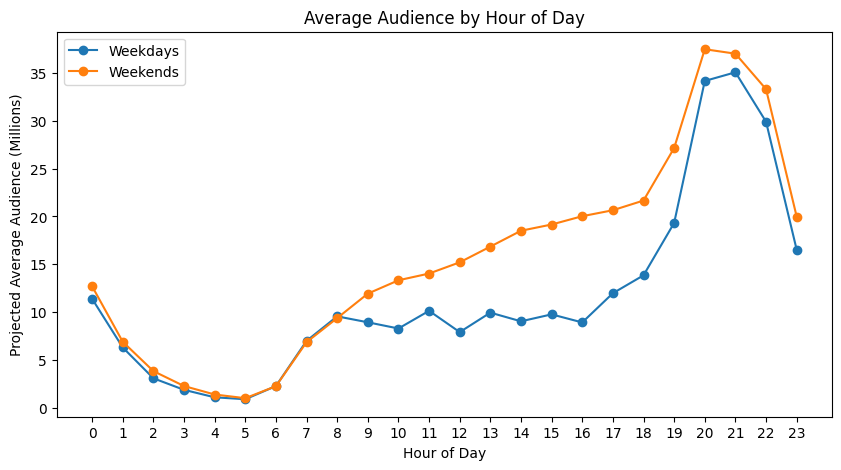

Peak hour, weekdays: 21
Peak hour, weekends: 20


In [12]:
v_pers = viewings[viewings['resp_type'].isin(['R', 'L'])]
starts = pd.DataFrame({'time': v_pers['start_ts'].dt.floor('min'), 'w': v_pers['weight']})
ends = pd.DataFrame({'time': v_pers['end_ts'].dt.floor('min'), 'w': -v_pers['weight']})
events = pd.concat([starts, ends]).groupby('time')['w'].sum()

min_idx = pd.date_range(events.index.min(), events.index.max(), freq='min')
ts = events.reindex(min_idx, fill_value=0.0).cumsum()

df_ts = ts.reset_index()
df_ts.columns = ['time', 'aud']
df_ts['hour'] = df_ts['time'].dt.hour
df_ts['b_date'] = (df_ts['time'] - pd.Timedelta(hours=6)).dt.date
df_ts['is_wknd'] = pd.to_datetime(df_ts['b_date']).dt.dayofweek >= 5

agg = df_ts.groupby(['is_wknd', 'hour'])['aud'].sum() / 60.0

bdates = pd.Series(pd.to_datetime(daily_weights['broadcast_date'].unique()))
n_wknd_days = (bdates.dt.dayofweek >= 5).sum()
n_wkdy_days = (bdates.dt.dayofweek < 5).sum()

wkdy_aud = agg[False] / n_wkdy_days / 1_000_000
wknd_aud = agg[True] / n_wknd_days / 1_000_000

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(wkdy_aud.index, wkdy_aud.values, label='Weekdays', marker='o')
ax.plot(wknd_aud.index, wknd_aud.values, label='Weekends', marker='o')
ax.set_xticks(range(24))
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Projected Average Audience (Millions)')
ax.set_title('Average Audience by Hour of Day')
ax.legend()
plt.show()

print("Peak hour, weekdays:", wkdy_aud.idxmax())
print("Peak hour, weekends:", wknd_aud.idxmax())

# **Answer:** The weekend viewership curve is flatter and shows significantly higher daytime audiences compared to weekdays, where viewership is heavily concentrated in the evening primetime hours.

### Task 1.3 - Session length

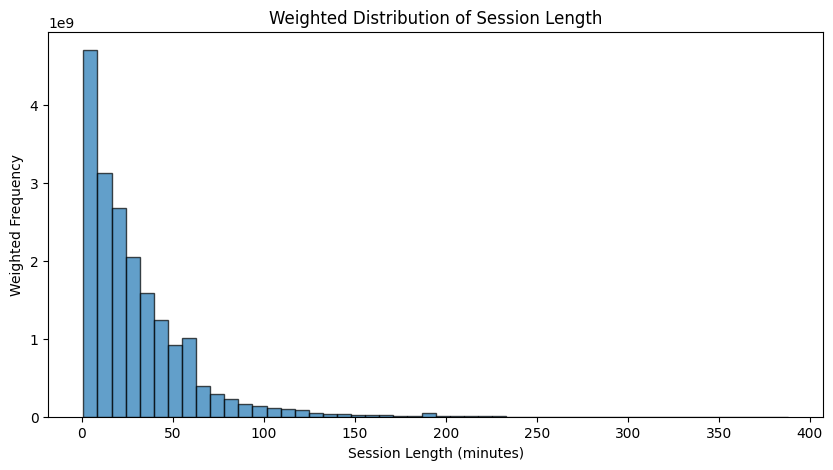

Session length, weighted mean (min): 29.37
Session length, weighted median (min): 21.0


In [13]:
v_pers = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()
v_pers['dur'] = (v_pers['end_ts'] - v_pers['start_ts']).dt.total_seconds() / 60.0

w_mean = (v_pers['dur'] * v_pers['weight']).sum() / v_pers['weight'].sum()

df_sorted = v_pers[['dur', 'weight']].sort_values('dur')
df_sorted['cum_w'] = df_sorted['weight'].cumsum()
midpoint = df_sorted['weight'].sum() / 2.0
w_median = df_sorted[df_sorted['cum_w'] >= midpoint]['dur'].iloc[0]

plt.figure(figsize=(10, 5))
plt.hist(v_pers['dur'], weights=v_pers['weight'], bins=50, edgecolor='black', alpha=0.7)
plt.xlabel('Session Length (minutes)')
plt.ylabel('Weighted Frequency')
plt.title('Weighted Distribution of Session Length')
plt.show()

print("Session length, weighted mean (min):", round(w_mean, 2))
print("Session length, weighted median (min):", round(w_median, 2))

# **Answer:** They differ because the distribution is heavily right-skewed, meaning a small number of very long viewing sessions pulls the mean significantly higher than the median. The median provides a more accurate representation of a typical viewer's behavior and is usually preferred for a client deck.

### Task 2 - Program reach curve

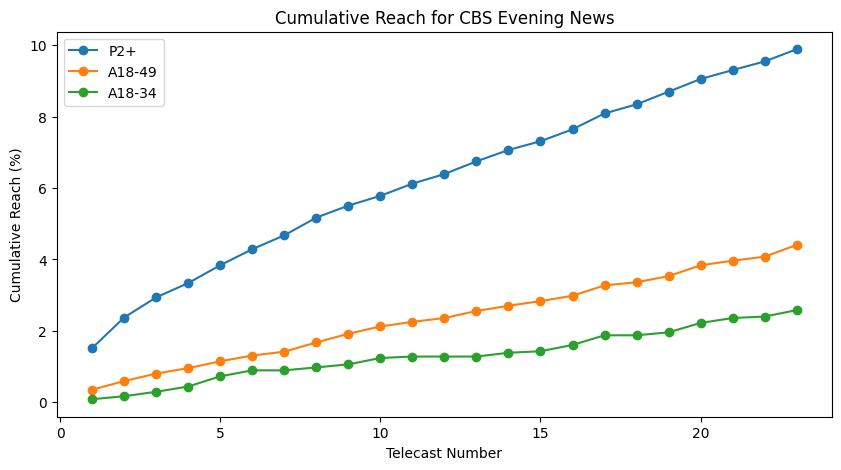

Telecasts of the program: 23
Average household rating (%): 3.2
Average P2+ rating (%): 1.6
Average projected audience (M): 4.93
Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4


In [14]:
cbs_news = programs[programs['program_name'] == 'CBS Evening News'].sort_values('start_ts')
v_cbs = viewings[viewings['network_code'] == 'CBS'].copy()

age_df = viewer_attributes[viewer_attributes['attr_id'] == 300][['respondent_id', 'value']].rename(columns={'value': 'age'})
sex_df = viewer_attributes[viewer_attributes['attr_id'].isin([201, 202])][['respondent_id', 'attr_id']].rename(columns={'attr_id': 'sex'})

dw_h = daily_weights[daily_weights['resp_type'] == 'H']
dw_p = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])].merge(age_df, on='respondent_id', how='left')

univ_h_daily = dw_h.groupby('broadcast_date')['weight'].sum()
univ_p2_daily = dw_p.groupby('broadcast_date')['weight'].sum()

avg_w_p = dw_p.groupby('respondent_id')['weight'].mean()
p_ages = age_df.set_index('respondent_id')['age']

univ_p2_reach = avg_w_p.sum()
univ_a1834_reach = avg_w_p[(p_ages >= 18) & (p_ages <= 34)].sum()
univ_a1849_reach = avg_w_p[(p_ages >= 18) & (p_ages <= 49)].sum()

t_ratings_h = []
t_ratings_p = []
t_aud_p = []
cum_viewers_p2 = set()
reach_p2 = []
reach_1834 = []
reach_1849 = []

for _, r in cbs_news.iterrows():
    p_start, p_end, b_date = r['start_ts'], r['end_ts'], r['broadcast_date']
    v = v_cbs[(v_cbs['start_ts'] < p_end) & (v_cbs['end_ts'] > p_start)].copy()

    if not v.empty:
        v['overlap'] = (v['end_ts'].clip(upper=p_end) - v['start_ts'].clip(lower=p_start)).dt.total_seconds() / 60.0
        v_qual = v[v['overlap'] >= 1.0]

        v_h = v_qual[v_qual['resp_type'] == 'H']['respondent_id'].unique()
        v_p = v_qual[v_qual['resp_type'].isin(['R', 'L'])]['respondent_id'].unique()

        w_h = dw_h[(dw_h['broadcast_date'] == b_date) & (dw_h['respondent_id'].isin(v_h))]['weight'].sum()
        w_p = dw_p[(dw_p['broadcast_date'] == b_date) & (dw_p['respondent_id'].isin(v_p))]['weight'].sum()

        t_ratings_h.append((w_h / univ_h_daily.get(b_date, 1)) * 100)
        t_ratings_p.append((w_p / univ_p2_daily.get(b_date, 1)) * 100)
        t_aud_p.append(w_p / 1_000_000)
        cum_viewers_p2.update(v_p)
    else:
        t_ratings_h.append(0)
        t_ratings_p.append(0)
        t_aud_p.append(0)

    vp_ages = p_ages.reindex(list(cum_viewers_p2))
    v_1834 = vp_ages[(vp_ages >= 18) & (vp_ages <= 34)].index
    v_1849 = vp_ages[(vp_ages >= 18) & (vp_ages <= 49)].index

    reach_p2.append(avg_w_p.reindex(list(cum_viewers_p2)).sum() / univ_p2_reach * 100)
    reach_1834.append(avg_w_p.reindex(v_1834).sum() / univ_a1834_reach * 100)
    reach_1849.append(avg_w_p.reindex(v_1849).sum() / univ_a1849_reach * 100)

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(reach_p2) + 1), reach_p2, label='P2+', marker='o')
plt.plot(range(1, len(reach_1849) + 1), reach_1849, label='A18-49', marker='o')
plt.plot(range(1, len(reach_1834) + 1), reach_1834, label='A18-34', marker='o')
plt.xlabel('Telecast Number')
plt.ylabel('Cumulative Reach (%)')
plt.title('Cumulative Reach for CBS Evening News')
plt.legend()
plt.show()

print("Telecasts of the program:", len(cbs_news))
print("Average household rating (%):", round(sum(t_ratings_h) / len(t_ratings_h), 1))
print("Average P2+ rating (%):", round(sum(t_ratings_p) / len(t_ratings_p), 1))
print("Average projected audience (M):", round(sum(t_aud_p) / len(t_aud_p), 2))
print("Final reach P2+ (%):", round(reach_p2[-1], 1))
print("Final reach A18-34 (%):", round(reach_1834[-1], 1))
print("Final reach A18-49 (%):", round(reach_1849[-1], 1))

# **Answer:** Cumulative reach grows steadily because each new telecast captures occasional viewers who haven't tuned in previously. The program reaches the older P2+ audience much better than younger demographics, which directly aligns with the universally older viewer base typical for traditional network evening news broadcasts.

### Task 3 - Program frequency

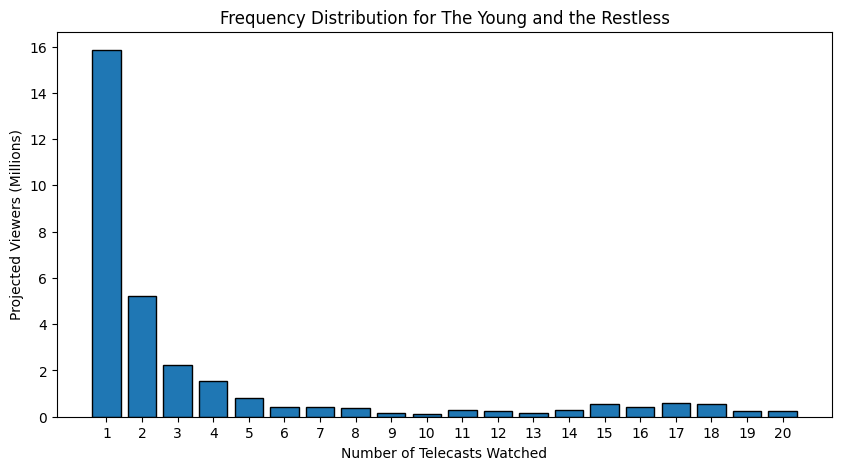

Projected viewers (M): 30.8
Average frequency (weighted): 3.6
Median frequency (weighted): 1
Share of views from the most loyal viewers: 0.704


In [15]:
y_and_r = programs[programs['program_name'] == 'The Young and the Restless'].sort_values('start_ts')
viewer_counts = {}

for _, r in y_and_r.iterrows():
    p_start, p_end = r['start_ts'], r['end_ts']
    v = v_cbs[(v_cbs['start_ts'] < p_end) & (v_cbs['end_ts'] > p_start)].copy()
    if not v.empty:
        v['overlap'] = (v['end_ts'].clip(upper=p_end) - v['start_ts'].clip(lower=p_start)).dt.total_seconds() / 60.0
        v_p = v[(v['overlap'] >= 1.0) & (v['resp_type'].isin(['R', 'L']))]['respondent_id'].unique()
        for resp in v_p:
            viewer_counts[resp] = viewer_counts.get(resp, 0) + 1

df_freq = pd.DataFrame(list(viewer_counts.items()), columns=['respondent_id', 'freq']).merge(avg_w_p.reset_index(), on='respondent_id', how='inner')

proj_viewers = df_freq['weight'].sum() / 1_000_000
avg_freq = (df_freq['freq'] * df_freq['weight']).sum() / df_freq['weight'].sum()

df_freq_s = df_freq.sort_values('freq')
df_freq_s['cum_w'] = df_freq_s['weight'].cumsum()
med_freq = df_freq_s[df_freq_s['cum_w'] >= df_freq_s['weight'].sum() / 2.0]['freq'].iloc[0]

thresh_80 = df_freq_s[df_freq_s['cum_w'] >= df_freq_s['weight'].sum() * 0.8]['freq'].iloc[0]
loyal = df_freq[df_freq['freq'] >= thresh_80]
loyal_share = (loyal['freq'] * loyal['weight']).sum() / (df_freq['freq'] * df_freq['weight']).sum()

freq_dist = df_freq.groupby('freq')['weight'].sum() / 1_000_000

plt.figure(figsize=(10, 5))
plt.bar(freq_dist.index, freq_dist.values, edgecolor='black')
plt.xlabel('Number of Telecasts Watched')
plt.ylabel('Projected Viewers (Millions)')
plt.title('Frequency Distribution for The Young and the Restless')
plt.xticks(range(1, max(freq_dist.index) + 1))
plt.show()

print("Projected viewers (M):", round(proj_viewers, 2))
print("Average frequency (weighted):", round(avg_freq, 1))
print("Median frequency (weighted):", round(med_freq, 1))
print("Share of views from the most loyal viewers:", round(loyal_share, 3))

# **Answer:** The average frequency is not a fair summary because the distribution is heavily polarized. A massive portion of viewers watches only one episode, while a small base of highly loyal viewers drives the vast majority of total views, making the average deceptive.

### Task 4 - Networks by age and gender

In [16]:
v_p_all = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()
v_p_all['dur'] = (v_p_all['end_ts'] - v_p_all['start_ts']).dt.total_seconds() / 60.0
v_p_all = v_p_all.merge(age_df, on='respondent_id', how='left').merge(sex_df, on='respondent_id', how='left')
v_p_all['proj_min'] = v_p_all['dur'] * v_p_all['weight']

def get_top_5(mask):
    return v_p_all[mask].groupby('network_code')['proj_min'].sum().nlargest(5)

print("Top 5 M18-34:\n", get_top_5((v_p_all['sex'] == 201) & (v_p_all['age'] >= 18) & (v_p_all['age'] <= 34)), "\n")
print("Top 5 W18-34:\n", get_top_5((v_p_all['sex'] == 202) & (v_p_all['age'] >= 18) & (v_p_all['age'] <= 34)), "\n")
print("Top 5 M35-54:\n", get_top_5((v_p_all['sex'] == 201) & (v_p_all['age'] >= 35) & (v_p_all['age'] <= 54)), "\n")
print("Top 5 W35-54:\n", get_top_5((v_p_all['sex'] == 202) & (v_p_all['age'] >= 35) & (v_p_all['age'] <= 54)), "\n")
print("Top 5 M55+:\n", get_top_5((v_p_all['sex'] == 201) & (v_p_all['age'] >= 55)), "\n")
print("Top 5 W55+:\n", get_top_5((v_p_all['sex'] == 202) & (v_p_all['age'] >= 55)), "\n")

net_1834 = v_p_all[(v_p_all['age'] >= 18) & (v_p_all['age'] <= 34)].groupby('network_code')['proj_min'].sum()
net_all = v_p_all.groupby('network_code')['proj_min'].sum()
share_1834 = (net_1834 / net_all).dropna()

net_1834_raw = v_p_all[(v_p_all['age'] >= 18) & (v_p_all['age'] <= 34)].groupby('network_code')['dur'].sum()
net_all_raw = v_p_all.groupby('network_code')['dur'].sum()
share_1834_raw = (net_1834_raw / net_all_raw).dropna()

print("Youngest network:", f"{share_1834.idxmax()} (Weighted: {round(share_1834.max(), 3)}, Raw: {round(share_1834_raw[share_1834.idxmax()], 3)})")
print("Oldest network:", f"{share_1834.idxmin()} (Weighted: {round(share_1834.min(), 3)}, Raw: {round(share_1834_raw[share_1834.idxmin()], 3)})")

Top 5 M18-34:
 network_code
FOX    4.386650e+09
NBC    3.910388e+09
CBS    3.044350e+09
ABC    3.010781e+09
FX     1.473963e+09
Name: proj_min, dtype: float64 

Top 5 W18-34:
 network_code
FOX    4.574441e+09
NBC    4.527593e+09
ABC    3.504858e+09
CBS    2.811222e+09
FX     1.383466e+09
Name: proj_min, dtype: float64 

Top 5 M35-54:
 network_code
FOX    1.280467e+10
NBC    1.098668e+10
ABC    9.037002e+09
CBS    8.134069e+09
FX     2.370803e+09
Name: proj_min, dtype: float64 

Top 5 W35-54:
 network_code
NBC     1.163910e+10
FOX     1.116139e+10
ABC     9.438556e+09
CBS     8.162798e+09
HGTV    3.051809e+09
Name: proj_min, dtype: float64 

Top 5 M55+:
 network_code
CBS    3.827403e+10
NBC    3.426741e+10
FOX    3.087851e+10
ABC    3.079334e+10
FNC    2.790371e+10
Name: proj_min, dtype: float64 

Top 5 W55+:
 network_code
CBS    4.712032e+10
NBC    4.139187e+10
ABC    3.884001e+10
FOX    3.691472e+10
FNC    3.145073e+10
Name: proj_min, dtype: float64 

Youngest network: FX (Weighted: 0

# **Answer:** Weighted and raw shares differ because physical panel demographics rarely match national census figures perfectly; some groups are consistently overrepresented or underrepresented. Relying on raw panel minutes would lead to skewed audience representations and severely misallocated advertising budgets.
#
# **Bonus answer:** I would pitch the oldest-skewing network to advertisers targeting young adults by highlighting robust co-viewing rates (younger adults watching alongside older relatives) or by offering significantly discounted CPMs, making that smaller slice of young viewers highly cost-efficient to reach.